# Hari 3: Scaling & KNN
**Study Group I-Smile Lab: EDA to Machine Learning**
Rabu, 7 Oktober 2026 · Telkom University

### Tujuan hari ini
Setelah sesi ini kamu bisa:
1. Membedakan regresi dan klasifikasi, lalu membuat target klasifikasi 0/1.
2. Membersihkan data sesuai kebutuhan KNN: missing value (termasuk yang tersamar), kolom teks, dan kolom yang tidak boleh jadi fitur.
3. Menjelaskan kenapa KNN butuh scaling, dan memakai `StandardScaler` dengan benar (fit di data latih saja).
4. Menilai model klasifikasi dengan accuracy, confusion matrix, precision, dan recall, lalu membandingkannya dengan baseline.
5. Melihat pengaruh nilai k terhadap hasil KNN.

### Alur sesi
| Waktu | Kegiatan | Isi notebook |
|---|---|---|
| Blok 1 (50 menit) | Dataset baru, disiapkan untuk KNN | Bagian 0 sampai 4 (± 44 menit) + cadangan ± 6 menit untuk tanya jawab |
| Break (10 menit) | Istirahat | |
| Blok 2 (50 menit) | KNN dan cara menilainya | Bagian 5 sampai 10 + penjelasan Tugas 3 (± 46 menit) + cadangan ± 4 menit untuk tanya jawab |

### Cara pakai notebook ini
1. Di Colab, pilih **File → Simpan salinan di Drive** supaya perubahanmu tersimpan di Drive sendiri.
2. Cari sel bertanda `# TODO`, lalu ganti setiap `___` dengan kode yang tepat.
3. Jalankan sel **setelah pengajar selesai menjelaskan slide** untuk topik itu. Selama pemaparan, cukup perhatikan dulu.
4. Jalankan sel **berurutan dari atas** dengan **Shift+Enter**. Kalau muncul error `NameError: name '...' is not defined`, berarti ada sel sebelumnya yang belum dijalankan (pakai menu *Runtime → Run before*).

Tanda yang dipakai di notebook ini:
- **Diskusi:** pertanyaan yang kita bahas bareng **sebelum** sel berikutnya dijalankan. Coba tebak dulu jawabannya.
- **Pengingat:** materi yang sudah dibahas di Hari 1 atau di slide. Jawabannya langsung ditulis, cukup dibaca.
- **Analogi:** perumpamaan sehari-hari, sama dengan yang ada di slide.
- Blockquote **Di dunia nyata**: versi lanjutan yang dipakai di industri. Cukup dipahami, tidak perlu dipraktikkan.

## 0. Persiapan (± 3 menit)
Library hari ini: `pandas`, `numpy`, `matplotlib`, dan `scikit-learn` (`sklearn`). Dari scikit-learn kita memakai model KNN, dua jenis scaler, dan metrik untuk klasifikasi.

In [ ]:
import pandas as pd               # mengolah tabel
import numpy as np                # operasi angka (NaN, akar, array)
import matplotlib.pyplot as plt   # membuat grafik

from sklearn.model_selection import train_test_split             # membagi data latih dan uji
from sklearn.preprocessing import StandardScaler, MinMaxScaler   # dua cara menyamakan skala kolom
from sklearn.neighbors import KNeighborsClassifier               # model KNN untuk klasifikasi
# metrik untuk menilai model klasifikasi
from sklearn.metrics import accuracy_score, precision_score, recall_score, confusion_matrix, ConfusionMatrixDisplay

pd.set_option("display.max_columns", None)  # tampilkan semua kolom saat print tabel
plt.rcParams["figure.figsize"] = (8, 4.5)   # ukuran bawaan semua grafik

Hari ini kita memakai **dataset baru**: data pasien penyakit jantung dari 4 rumah sakit (Heart Disease UCI). File yang dibaca adalah file **mentah**, jadi cleaning-nya kita lakukan sendiri di notebook ini.

In [ ]:
# Lokasi dataset. Di Colab, ganti dengan link Google Drive, misalnya:
# DATA_PATH = "https://drive.google.com/uc?id=ISI_ID_FILE_DI_SINI"
DATA_PATH = "heart_disease_uci.csv"

df = pd.read_csv(DATA_PATH)   # baca file CSV menjadi tabel (DataFrame)
# berhenti dengan pesan error kalau ukuran data salah (salah file)
assert df.shape == (920, 16), f"Ukuran data {df.shape}, seharusnya (920, 16). Cek lagi file-nya."
print("Ukuran data (baris, kolom):", df.shape)
df.head()   # tampilkan 5 baris pertama

Ukuran data (baris, kolom): (920, 16)


,id,age,sex,dataset,cp,trestbps,chol,fbs,restecg,thalch,exang,oldpeak,slope,ca,thal,num
0,1,63,Male,Cleveland,typical angina,145.0,233.0,True,lv hypertrophy,150.0,False,2.3,downsloping,0.0,fixed defect,0
1,2,67,Male,Cleveland,asymptomatic,160.0,286.0,False,lv hypertrophy,108.0,True,1.5,flat,3.0,normal,2
2,3,67,Male,Cleveland,asymptomatic,120.0,229.0,False,lv hypertrophy,129.0,True,2.6,flat,2.0,reversable defect,1
3,4,37,Male,Cleveland,non-anginal,130.0,250.0,False,normal,187.0,False,3.5,downsloping,0.0,normal,0
4,5,41,Female,Cleveland,atypical angina,130.0,204.0,False,lv hypertrophy,172.0,False,1.4,upsloping,0.0,normal,0


### Kamus kolom
**1 baris = 1 pasien.**

| Kolom | Arti | Jenis |
|---|---|---|
| `id` | Nomor urut pasien | Nomor |
| `age` | Umur (tahun) | Angka |
| `sex` | Jenis kelamin | Kategori (teks) |
| `dataset` | Asal rumah sakit (Cleveland, Hungary, Switzerland, VA Long Beach) | Kategori (teks) |
| `cp` | Tipe nyeri dada: typical angina, atypical angina, non-anginal, asymptomatic (tanpa gejala) | Kategori (teks) |
| `trestbps` | Tekanan darah saat istirahat (mmHg) | Angka |
| `chol` | Kadar kolesterol darah (mg/dl) | Angka |
| `fbs` | Gula darah puasa > 120 mg/dl (True/False) | Kategori (True/False) |
| `restecg` | Hasil EKG saat istirahat: normal, st-t abnormality, lv hypertrophy | Kategori (teks) |
| `thalch` | Detak jantung maksimum saat tes treadmill | Angka |
| `exang` | Nyeri dada muncul saat olahraga (True/False) | Kategori (True/False) |
| `oldpeak` | Penurunan segmen ST pada EKG saat olahraga dibanding istirahat | Angka |
| `slope` | Kemiringan segmen ST saat olahraga puncak | Kategori (teks) |
| `ca` | Jumlah pembuluh darah utama yang terlihat pada fluoroskopi (0–3) | Angka |
| `thal` | Hasil tes thalium: normal, fixed defect, reversable defect | Kategori (teks) |
| `num` | Diagnosis: 0 = tidak ada penyakit jantung, 1–4 = ada penyakit (makin besar makin parah) | Angka. **Ini yang mau ditebak** |

Kalian tidak perlu hafal istilah medisnya. Yang penting kalian tahu kolom mana yang berisi **angka** dan mana yang berisi **kategori**, karena keduanya diperlakukan berbeda.

---
# Blok 1: Dataset baru, disiapkan untuk KNN (± 50 menit)
Hari ini kita memakai model **KNN (K-Nearest Neighbors)**. KNN menebak dengan melihat pasien-pasien yang paling **mirip**, dan kemiripan diukur dengan **jarak** antar baris. Karena itu KNN gagal kalau:
1. ada **nilai kosong** (jarak ke "kosong" tidak bisa dihitung),
2. ada **teks** (jarak antara "Male" dan "Female" berapa?),
3. **skala kolom berbeda jauh** (kolom berangka ratusan menenggelamkan kolom berangka satuan).

Seluruh EDA dan cleaning di blok ini diarahkan ke tiga hal itu.

## 1. Dari regresi ke klasifikasi (± 5 menit)
Kolom yang mau ditebak adalah `num`. Kita lihat dulu isinya.

In [ ]:
# TODO: hitung jumlah pasien untuk tiap nilai num, lalu urutkan dari 0 sampai 4
df["num"].value_counts().sort_index()   # sort_index: urut menurut nilai num, bukan jumlahnya

,count
num,
0,411
1,265
2,109
3,107
4,28


- Di **Hari 2** kita menebak **angka** (harga rumah). Tebakannya bisa meleset sedikit atau banyak. Ini disebut **regresi**.
- Hari ini kita menebak **kategori**: pasien ini **sehat** atau **sakit**. Ini disebut **klasifikasi**.

Kolom `num` berisi 0–4. Nanti di Bagian 3 kolom ini diubah menjadi target 0/1 (0 = sehat, 1 = sakit).

**Diskusi:** Kalau model menebak harga USD 250.000 padahal aslinya USD 260.000, tebakannya meleset sedikit. Kalau model menebak "sehat" padahal pasiennya sakit, melesetnya seberapa? Bisa diukur pakai MAE tidak?

## 2. EDA cepat untuk kebutuhan KNN (± 10 menit)
Tidak semua EDA Hari 1 kita ulang. Kita hanya mencari hal yang **mengganggu perhitungan jarak**: rentang angka yang berbeda jauh, nilai yang aneh, dan pola yang bisa menipu model.

### 2a. Ringkasan kolom angka

In [ ]:
df.describe().round(2)   # statistik ringkas tiap kolom angka, dibulatkan 2 desimal

,id,age,trestbps,chol,thalch,oldpeak,ca,num
count,920.00,920.00,861.00,890.00,865.00,858.00,309.00,920.00
mean,460.50,53.51,132.13,199.13,137.55,0.88,0.68,1.00
std,265.73,9.42,19.07,110.78,25.93,1.09,0.94,1.14
min,1.00,28.00,0.00,0.00,60.00,-2.60,0.00,0.00
25%,230.75,47.00,120.00,175.00,120.00,0.00,0.00,0.00
50%,460.50,54.00,130.00,223.00,140.00,0.50,0.00,1.00
75%,690.25,60.00,140.00,268.00,157.00,1.50,1.00,2.00
max,920.00,77.00,200.00,603.00,202.00,6.20,3.00,4.00


**Diskusi:** Bandingkan rentang `chol` (min sampai max) dengan rentang `oldpeak`. Apa yang terjadi kalau dua kolom ini dipakai untuk menghitung jarak antar pasien? Lalu perhatikan nilai **minimum** `chol`. Masuk akal?

### 2b. Sebaran kolesterol

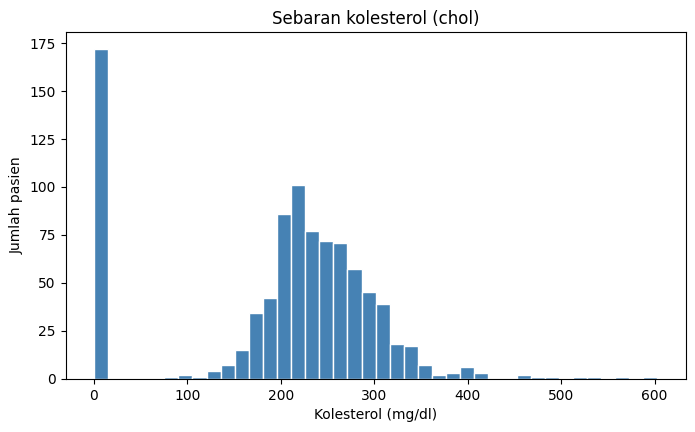

In [ ]:
# TODO: buat histogram chol dengan 40 bins
plt.hist(df["chol"], bins=40, color="steelblue", edgecolor="white")   # bins = jumlah batang
plt.title("Sebaran kolesterol (chol)")
plt.xlabel("Kolesterol (mg/dl)")
plt.ylabel("Jumlah pasien")
plt.show()

Perhatikan batang paling kiri, di angka **0**. Batang itu terpisah jauh dari sebaran utama.

### 2c. Kolesterol 0 berasal dari mana?
Kita hitung baris dengan `chol == 0` per rumah sakit, lalu bandingkan dengan jumlah pasien tiap rumah sakit.

In [ ]:
# .loc[kondisi, kolom]: ambil kolom dataset dari baris yang chol = 0
chol_nol = df.loc[df["chol"] == 0, "dataset"].value_counts()
total_pasien = df["dataset"].value_counts()   # jumlah semua pasien per rumah sakit

# gabung jadi satu tabel; RS tanpa chol = 0 diisi 0, lalu jadi bilangan bulat
pd.DataFrame({"jumlah chol = 0": chol_nol, "total pasien": total_pasien}).fillna(0).astype(int)

,jumlah chol = 0,total pasien
dataset,,
Cleveland,0,304
Hungary,0,293
Switzerland,123,123
VA Long Beach,49,200


**Diskusi:** Kolesterol 0 numpuk di rumah sakit mana? Ini pasien yang kolesterolnya benar-benar nol, atau rumah sakit itu tidak mencatat?

### 2d. Proporsi pasien sakit per rumah sakit
`num > 0` menghasilkan True (sakit) atau False (sehat). Rata-rata dari True/False sama dengan **proporsi** True, karena True dihitung 1 dan False dihitung 0.

In [ ]:
# True/False per pasien, dirata-rata per rumah sakit = proporsi sakit
proporsi_sakit = (df["num"] > 0).groupby(df["dataset"]).mean()
proporsi_sakit.round(2).sort_values()   # urutkan dari proporsi terkecil

,num
dataset,
Hungary,0.36
Cleveland,0.46
VA Long Beach,0.74
Switzerland,0.93


Simpan angka ini di kepala. Kita pakai lagi di Bagian 3d.

### 2e. Umur dan detak jantung maksimum
Setiap titik adalah satu pasien, diberi warna sesuai kondisinya.

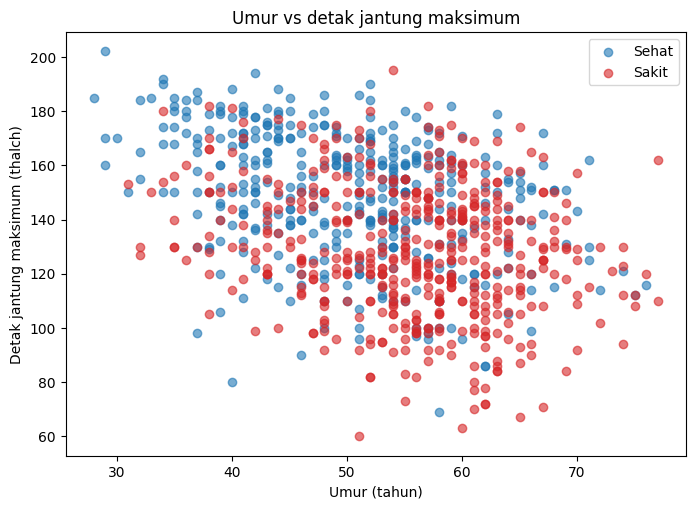

In [ ]:
pasien_sehat = df[df["num"] == 0]   # baris pasien sehat
pasien_sakit = df[df["num"] > 0]    # baris pasien sakit (num 1 sampai 4)

plt.figure(figsize=(8, 5.5))
# dua scatter ditumpuk: biru = sehat, merah = sakit
plt.scatter(pasien_sehat["age"], pasien_sehat["thalch"], alpha=0.6, color="tab:blue", label="Sehat")
plt.scatter(pasien_sakit["age"], pasien_sakit["thalch"], alpha=0.6, color="tab:red", label="Sakit")
plt.title("Umur vs detak jantung maksimum")
plt.xlabel("Umur (tahun)")
plt.ylabel("Detak jantung maksimum (thalch)")
plt.legend()
plt.show()

**Diskusi:** Pasien sakit cenderung mengumpul di area mana? Kalau ada pasien baru di titik tertentu, kira-kira kita tebak dia sakit atau sehat dengan melihat apa?

## 3. Recall cleaning: hanya yang dibutuhkan KNN (± 18 menit)
KNN tidak bisa jalan kalau ada NaN, tidak bisa menghitung jarak dari teks, dan dikuasai kolom berskala besar. Hari ini kita hanya membersihkan hal-hal yang membuat KNN gagal.

Seluruh bagian ini **demonstrasi**. Keputusan yang baru hari ini kita diskusikan dulu. Yang sudah dibahas di Hari 1 cukup diingatkan. Kita bekerja di salinan data, `df_clean`, supaya `df` asli tetap utuh.

In [ ]:
df_clean = df.copy()   # salinan terpisah, jadi df asli tidak ikut berubah

### 3a. Missing value
Persentase nilai kosong per kolom, diurutkan dari yang terbanyak:

In [ ]:
# isnull().mean() = proporsi sel kosong per kolom; dikali 100 jadi persen
persen_missing = (df_clean.isnull().mean() * 100).round(1).sort_values(ascending=False)
persen_missing   # urut dari yang paling banyak kosong

,0
ca,66.4
thal,52.8
slope,33.6
fbs,9.8
oldpeak,6.7
trestbps,6.4
exang,6.0
thalch,6.0
chol,3.3
restecg,0.2


**Diskusi:** `ca` kosong 66%, `thal` 53%, `slope` 34%. Diisi atau dibuang?

**Keputusan:** kolom yang kosong **lebih dari sepertiga** dibuang. Mengisi sebanyak itu berarti mengarang sebagian besar isinya.

In [ ]:
# nama kolom yang kosongnya lebih dari sepertiga (33,3%)
kolom_buang = persen_missing[persen_missing > 100 / 3].index.tolist()
df_clean = df_clean.drop(columns=kolom_buang)   # buang kolom-kolom itu

print("Kolom yang dibuang:", kolom_buang)
print("Ukuran df_clean   :", df_clean.shape)

Kolom yang dibuang: ['ca', 'thal', 'slope']
Ukuran df_clean   : (920, 13)


Tiga kolom (`ca`, `thal`, `slope`) dibuang, tersisa 13 kolom. Kolom lain kosongnya di bawah 10%, jadi nanti diisi.

### 3b. Missing tersamar

**Diskusi:** Di Hari 1 kita bertanya: outlier itu **salah** atau **jarang**? Kolesterol 0 dan tekanan darah 0 masuk yang mana?

**Keputusan:** keduanya **salah**, karena mustahil pada orang hidup. Nilai 0 itu sebenarnya data yang tidak dicatat, jadi kita ubah menjadi `np.nan` supaya ikut diisi bersama missing value lainnya di 3c.

**Analogi:** Siswa yang tidak ikut ujian dicatat bernilai 0, sehingga rata-rata kelas turun padahal tidak ada yang benar-benar mendapat 0.

Polanya: `df.loc[kondisi, kolom] = nilai_baru` artinya "pada baris yang kondisinya True, ganti isi kolom ini".

In [ ]:
print("chol = 0     :", (df_clean["chol"] == 0).sum(), "baris")
print("trestbps = 0 :", (df_clean["trestbps"] == 0).sum(), "baris")

# .loc[kondisi, kolom] = nilai: ganti isi kolom hanya di baris yang True
df_clean.loc[df_clean["chol"] == 0, "chol"] = np.nan             # kolesterol 0 jadi kosong
df_clean.loc[df_clean["trestbps"] == 0, "trestbps"] = np.nan     # tekanan darah 0 jadi kosong

chol = 0     : 172 baris
trestbps = 0 : 1 baris


Bagaimana dengan `oldpeak`? Kita hitung nilai negatifnya:

In [ ]:
print("oldpeak < 0:", (df_clean["oldpeak"] < 0).sum(), "baris")
print("Minimum    :", df_clean["oldpeak"].min())

oldpeak < 0: 12 baris
Minimum    : -2.6


**Diskusi:** `oldpeak` negatif, salah atau jarang?

**Keputusan:** **dibiarkan**. Secara medis nilai negatif bisa terjadi (segmen ST naik, bukan turun), jadi ini data yang jarang, bukan data yang salah.

Sekarang lihat jumlah missing setelah nilai 0 diganti:

In [ ]:
jumlah_missing = df_clean.isnull().sum()   # jumlah sel kosong per kolom
jumlah_missing[jumlah_missing > 0]         # tampilkan kolom yang masih ada kosongnya

,0
trestbps,60
chol,202
fbs,90
restecg,2
thalch,55
exang,55
oldpeak,62


`chol` yang tadinya hanya kosong 30 baris sekarang kosong 202 baris. Ini jumlah yang sebenarnya.

### 3c. Mengisi missing value

**Pengingat:** kolom angka (`trestbps`, `chol`, `thalch`, `oldpeak`) diisi **median**, karena median tidak mudah tertarik nilai ekstrem (ingat `chol` sampai 603). Kolom kategori (`fbs`, `restecg`, `exang`) diisi **modus**, karena kategori tidak punya rata-rata, jadi yang masuk akal adalah nilai yang paling sering muncul.

Di Hari 1 kita mengisi dengan `fillna`. Di sini kita pakai pola `.loc` yang sama seperti 3b: pilih baris yang kosong, lalu isi nilainya. Hasilnya sama persis.

In [ ]:
kolom_angka = ["trestbps", "chol", "thalch", "oldpeak"]   # diisi median
kolom_kategori = ["fbs", "restecg", "exang"]              # diisi modus

for kolom in kolom_angka:                                     # ulangi untuk tiap kolom angka
    nilai_isi = df_clean[kolom].median()                      # nilai tengah, tahan nilai ekstrem
    df_clean.loc[df_clean[kolom].isnull(), kolom] = nilai_isi  # isi baris yang kosong saja
    print(f"{kolom:9} diisi median: {nilai_isi}")

for kolom in kolom_kategori:                                  # ulangi untuk tiap kolom kategori
    nilai_isi = df_clean[kolom].mode()[0]                     # nilai paling sering; [0] = yang pertama
    df_clean.loc[df_clean[kolom].isnull(), kolom] = nilai_isi  # isi baris yang kosong saja
    print(f"{kolom:9} diisi modus : {nilai_isi}")

print()
print("Sisa missing:", df_clean.isnull().sum().sum())

trestbps  diisi median: 130.0
chol      diisi median: 239.5
thalch    diisi median: 140.0
oldpeak   diisi median: 0.5
fbs       diisi modus : False
restecg   diisi modus : normal
exang     diisi modus : False

Sisa missing: 0


Semua nilai kosong sudah terisi. KNN tidak akan lagi gagal karena NaN.

### 3d. Kolom yang tidak dipakai
`id` hanya nomor urut, tidak ada hubungannya dengan penyakit. Tapi KNN tidak tahu itu: kalau `id` ikut dihitung, pasien nomor 1 dan nomor 2 dianggap "mirip" hanya karena nomornya berdekatan. Jadi `id` dibuang.

In [ ]:
df_clean = df_clean.drop(columns="id")   # buang kolom id (nomor urut, bukan gejala)
print("Kolom tersisa:", df_clean.columns.tolist())

Kolom tersisa: ['age', 'sex', 'dataset', 'cp', 'trestbps', 'chol', 'fbs', 'restecg', 'thalch', 'exang', 'oldpeak', 'num']


**Diskusi:** Kolom `dataset` (asal rumah sakit) boleh jadi fitur tidak? Lihat lagi output 2d.

**Keputusan:** `dataset` **tidak dipakai sebagai fitur**. Kolomnya tetap disimpan di `df_clean`, lalu dibuang saat membentuk `X` di Bagian 4.

### 3e. Target: sehat atau sakit

**Pengingat:** `num` yang berisi 0–4 kita jadikan 0/1 karena pertanyaan kita hanya "ada penyakit atau tidak". Selain itu kelas 4 hanya 28 pasien, terlalu sedikit untuk dipelajari sendiri.

In [ ]:
df_clean["target"] = (df_clean["num"] > 0).astype(int)   # True/False jadi 1/0: 1 = sakit, 0 = sehat

print(df_clean["target"].value_counts())
print(f"Proporsi sakit: {df_clean['target'].mean():.1%}")

target
1    509
0    411
Name: count, dtype: int64
Proporsi sakit: 55.3%


Datanya **cukup seimbang**: sekitar 55% sakit dan 45% sehat. Ingat angka ini, karena penting saat membaca accuracy di Blok 2.

### 3f. Encoding kolom teks

**Pengingat:** KNN menghitung jarak, dan jarak tidak bisa dihitung dari teks seperti "Male" dan "Female", jadi semua teks harus diubah menjadi angka. `cp` (4 tipe nyeri dada) tidak cukup diberi label 0, 1, 2, 3, karena label angka membuat urutan dan jarak palsu, dan di KNN jarak palsu itu langsung menentukan siapa yang dianggap tetangga.

- `sex`, `fbs`, dan `exang` hanya punya dua nilai, jadi cukup diubah menjadi 1/0.
- `cp` dan `restecg` punya lebih dari dua kategori yang **tidak berurutan**, jadi di-one-hot dengan `pd.get_dummies` seperti di Hari 1.

In [ ]:
df_clean["sex"] = (df_clean["sex"] == "Male").astype(int)   # Male = 1, Female = 0
df_clean["fbs"] = df_clean["fbs"].astype(int)               # True = 1, False = 0
df_clean["exang"] = df_clean["exang"].astype(int)           # True = 1, False = 0

# one-hot: tiap kategori jadi kolom 0/1; drop_first membuang satu kolom
df_clean = pd.get_dummies(df_clean, columns=["cp", "restecg"], drop_first=True, dtype=int)
df_clean.head()   # cek hasil encoding

,age,sex,dataset,trestbps,chol,fbs,thalch,exang,oldpeak,num,target,cp_atypical angina,cp_non-anginal,cp_typical angina,restecg_normal,restecg_st-t abnormality
0,63,1,Cleveland,145.0,233.0,1,150.0,0,2.3,0,0,0,0,1,0,0
1,67,1,Cleveland,160.0,286.0,0,108.0,1,1.5,2,1,0,0,0,0,0
2,67,1,Cleveland,120.0,229.0,0,129.0,1,2.6,1,1,0,0,0,0,0
3,37,1,Cleveland,130.0,250.0,0,187.0,0,3.5,0,0,0,1,0,1,0
4,41,0,Cleveland,130.0,204.0,0,172.0,0,1.4,0,0,1,0,0,0,0


Kategori yang di-drop oleh `drop_first=True` adalah kategori pertama menurut abjad: `cp` = **asymptomatic** dan `restecg` = **lv hypertrophy**. Pasien yang semua kolom `cp_*`-nya 0 berarti tipe nyeri dadanya asymptomatic.

### 3g. Cek akhir

In [ ]:
print("Ukuran df_clean:", df_clean.shape)
print("Total missing  :", df_clean.isnull().sum().sum())
# select_dtypes(exclude="number"): ambil kolom yang tipenya bukan angka
print("Kolom bukan angka:", df_clean.select_dtypes(exclude="number").columns.tolist())

Ukuran df_clean: (920, 16)
Total missing  : 0
Kolom bukan angka: ['dataset']


Tidak ada nilai kosong, dan satu-satunya kolom yang bukan angka adalah `dataset`, yang memang tidak dipakai sebagai fitur.

**Ringkasan cleaning hari ini:**

| Masalah | Tindakan | Kenapa KNN butuh ini |
|---|---|---|
| `ca`, `thal`, `slope` kosong lebih dari sepertiga | Kolom dibuang | Mengisi sebanyak itu sama dengan mengarang data |
| `chol` = 0 dan `trestbps` = 0 (missing tersamar) | Diganti NaN, lalu diisi | Nilai 0 palsu membuat jarak ke pasien lain jadi salah |
| Nilai kosong di 7 kolom | Angka diisi median, kategori diisi modus | KNN error kalau ada NaN |
| `id` dan `dataset` | Tidak dipakai sebagai fitur | `id` membuat "kemiripan" palsu, `dataset` membuat model belajar asal rumah sakit, bukan gejala |
| `sex`, `fbs`, `exang`, `cp`, `restecg` berupa teks/True-False | 1/0 dan one-hot | Jarak tidak bisa dihitung dari teks |
| Target `num` 0–4 | Dijadikan `target` 0/1 | Pertanyaannya "sakit atau tidak" |

Masih ada satu masalah yang **belum** ditangani: skala kolom yang berbeda jauh. Itu kita bahas di Bagian 6, setelah melihat sendiri akibatnya.

> **Di dunia nyata (cukup dipahami, tidak dipraktikkan):** Kolom dengan banyak missing tidak selalu dibuang. Bisa ditambah kolom penanda "data ini kosong", karena kosongnya sendiri bisa jadi informasi (misalnya tes `ca` hanya dilakukan ke pasien tertentu). Median juga seharusnya dihitung dari **data latih saja**, dan sering dihitung **per kelompok** (misalnya per rumah sakit).

## 4. Fitur, target, dan split (± 8 menit)
Sama seperti Hari 2: `X` berisi kolom untuk menebak, `y` berisi jawaban. Yang **tidak boleh** masuk `X`:
- `target` dan `num`: keduanya kunci jawaban (`target` dibuat dari `num`).
- `dataset`: keputusan di 3d.

In [ ]:
# TODO: bentuk X (buang kolom num, target, dan dataset) dan y (kolom target)
X = df_clean.drop(columns=["num", "target", "dataset"])   # fitur: buang kolom jawaban dan bukan fitur
y = df_clean["target"]   # jawaban yang mau ditebak (0 = sehat, 1 = sakit)

print("Ukuran X:", X.shape)
print("Ukuran y:", y.shape)

Ukuran X: (920, 13)
Ukuran y: (920,)


Split 80:20 seperti Hari 2, dengan satu tambahan: `stratify=y`. Parameter ini menjaga **proporsi pasien sakit** tetap sama di data latih dan data uji.

**Analogi:** Kelas yang berisi 60% laki-laki disurvei dengan sampel yang juga 60% laki-laki, supaya hasil survei mewakili kelas.

In [ ]:
# TODO: bagi data 80:20 dengan random_state=42, dan jaga proporsi kelas memakai stratify
# test_size=0.2: 20% jadi data uji | random_state=42: hasil acak selalu sama
# stratify: proporsi pasien sakit di data latih dan uji dibuat sama
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

print("X_train:", X_train.shape, "| X_test:", X_test.shape)

X_train: (736, 13) | X_test: (184, 13)


In [ ]:
print(f"Proporsi sakit di y      : {y.mean():.1%}")
print(f"Proporsi sakit di y_train: {y_train.mean():.1%}")
print(f"Proporsi sakit di y_test : {y_test.mean():.1%}")
print()
print("Isi data uji:", (y_test == 1).sum(), "sakit,", (y_test == 0).sum(), "sehat")

Proporsi sakit di y      : 55.3%
Proporsi sakit di y_train: 55.3%
Proporsi sakit di y_test : 55.4%

Isi data uji: 102 sakit, 82 sehat


**Diskusi:** Apa gunanya `stratify`? Apa jadinya kalau data uji kebetulan berisi 80% pasien sakit?

---
# Break (10 menit)
Istirahat dulu. Pastikan semua sel di atas sudah jalan tanpa error sebelum lanjut.

---

# Blok 2: KNN dan cara menilainya (± 50 menit)

## 5. KNN pertama, tanpa scaling (± 8 menit)
Cara kerja KNN untuk menebak satu pasien baru:
1. Hitung **jarak** pasien baru ke **semua** pasien di data latih.
2. Ambil **k pasien terdekat** (tetangga).
3. **Voting mayoritas**: kalau kebanyakan tetangganya sakit, pasien baru ditebak sakit.

**Analogi:** Selera makan seseorang ditebak dari selera 5 teman terdekatnya.

Bedanya dengan regresi linear di Hari 2: `.fit()` pada KNN **tidak mencari rumus apa pun**, hanya **menyimpan** data latih. Perhitungan jarak baru terjadi saat `.predict()`.

### Baseline
Seperti Hari 2, kita butuh pembanding paling sederhana. Di Hari 2 baseline-nya selalu menebak **rata-rata** harga. Di klasifikasi tidak ada rata-rata kategori, jadi baseline-nya selalu menebak **kelas terbanyak** di data latih, untuk semua pasien.

Ukuran pertama untuk klasifikasi adalah **accuracy**:

$$\text{accuracy} = \frac{\text{jumlah tebakan benar}}{\text{jumlah data}}$$

In [ ]:
kelas_terbanyak = y_train.mode()[0]   # kelas paling sering di data latih
pred_baseline = np.full(len(y_test), kelas_terbanyak)   # tebakan yang sama untuk semua pasien uji

acc_baseline = accuracy_score(y_test, pred_baseline)   # proporsi tebakan yang benar
print("Baseline selalu menebak:", kelas_terbanyak, "(1 = Sakit)")
print(f"Accuracy baseline: {acc_baseline:.1%}")

Baseline selalu menebak: 1 (1 = Sakit)
Accuracy baseline: 55.4%


Sekarang KNN dengan k = 5 (5 tetangga terdekat), memakai data yang **belum di-scaling**.

In [ ]:
# TODO: latih KNN (k=5) dengan data latih, lalu tebak data uji
knn_tanpa_scaling = KNeighborsClassifier(n_neighbors=5)   # siapkan KNN dengan 5 tetangga
knn_tanpa_scaling.fit(X_train, y_train)   # model menyimpan data latih (fitur dan target)
pred_tanpa_scaling = knn_tanpa_scaling.predict(X_test)   # hitung jarak + voting untuk tiap pasien

In [ ]:
# TODO: hitung accuracy KNN tanpa scaling. Urutan argumen: (y_aktual, y_prediksi)
acc_tanpa_scaling = accuracy_score(y_test, pred_tanpa_scaling)   # proporsi tebakan yang benar
print(f"Accuracy KNN tanpa scaling: {acc_tanpa_scaling:.1%}")

Accuracy KNN tanpa scaling: 67.9%


**Diskusi:** Lebih baik dari baseline? Lebih baik berapa poin?

Hasil tebakan disimpan di `pred_tanpa_scaling`. Variabel ini dipakai lagi di Bagian 7 dan 8.

## 6. Kenapa KNN butuh scaling (± 10 menit)
### Demonstrasi: jarak tiga pasien
Bayangkan tiga pasien buatan, dengan dua kolom saja:

| Pasien | `age` | `chol` |
|---|---|---|
| A | 40 | 200 |
| B | 70 | 205 |
| C | 41 | 260 |

Mana yang lebih mirip dengan A, pasien B atau C? Jarak dihitung dengan **jarak Euclidean**:

$$\text{jarak} = \sqrt{(\Delta \text{age})^2 + (\Delta \text{chol})^2}$$

Kita hitung dua kali: dengan angka mentah, lalu setelah selisih tiap kolom **dibagi standar deviasi** kolom itu di `X_train`, supaya skala kedua kolom setara.

In [ ]:
# tiga pasien buatan, dua kolom saja
pasien = pd.DataFrame({"age": [40, 70, 41], "chol": [200, 205, 260]}, index=["A", "B", "C"])
std_train = X_train[["age", "chol"]].std()   # sebaran umum age dan chol di data latih
print("Standar deviasi di X_train:", std_train.round(1).to_dict())

selisih_AB = pasien.loc["A"] - pasien.loc["B"]   # selisih age dan chol antara A dan B
selisih_AC = pasien.loc["A"] - pasien.loc["C"]   # selisih age dan chol antara A dan C

# jarak Euclidean: kuadratkan selisih, jumlahkan, lalu akarkan
tabel_jarak = pd.DataFrame({
    "jarak mentah": [np.sqrt((selisih_AB ** 2).sum()), np.sqrt((selisih_AC ** 2).sum())],
    # rumus yang sama, tapi selisih dibagi std dulu supaya skala setara
    "jarak setelah dibagi std": [np.sqrt(((selisih_AB / std_train) ** 2).sum()),
                                 np.sqrt(((selisih_AC / std_train) ** 2).sum())],   # A ke C
}, index=["A ke B", "A ke C"])   # nama baris tabel
tabel_jarak.round(1)   # tampilkan, dibulatkan 1 desimal

Standar deviasi di X_train: {'age': 9.4, 'chol': 53.7}


,jarak mentah,jarak setelah dibagi std
A ke B,30.4,3.2
A ke C,60.0,1.1


Dengan angka mentah, **B lebih dekat ke A**, padahal B 30 tahun lebih tua. Setelah skalanya disamakan, **C yang lebih dekat**. Tanpa scaling, selisih kolesterol 60 dianggap lebih besar daripada selisih umur 30 tahun, hanya karena satuan kolesterol lebih besar.

**Analogi:** Membandingkan orang dari umur (tahun) dan gaji (rupiah): selisih gaji Rp100.000 terlihat lebih besar daripada selisih umur 30 tahun, padahal Rp100.000 itu kecil.

**Diskusi:** Di Hari 2, regresi linear tidak kita scaling dan hasilnya baik-baik saja. Kenapa KNN beda?

### StandardScaler
`StandardScaler` mengubah setiap kolom supaya rata-ratanya 0 dan standar deviasinya 1:

$$z = \frac{x - \text{mean}}{\text{std}}$$

Caranya dua langkah: `fit` menghitung mean dan std tiap kolom, lalu `transform` memakai angka itu untuk mengubah data.

In [ ]:
scaler = StandardScaler()   # siapkan scaler: tiap kolom jadi mean 0, std 1
scaler.fit(X_train)         # hitung mean dan std dari data latih saja

StandardScaler()

In [ ]:
# TODO: ubah data latih dan data uji memakai scaler yang sudah di-fit di data latih
X_train_scaled = scaler.transform(X_train)   # ubah data latih memakai mean dan std tadi
X_test_scaled = scaler.transform(X_test)   # data uji diubah dengan mean dan std yang SAMA

In [ ]:
kolom_contoh = ["age", "trestbps", "chol", "oldpeak"]   # empat kolom untuk dicek
# hasil transform berupa array; dijadikan tabel lagi supaya mudah dicek
X_train_scaled_tabel = pd.DataFrame(X_train_scaled, columns=X_train.columns)

# bandingkan mean dan std sebelum dan sesudah scaling
pd.DataFrame({
    "mean sebelum": X_train[kolom_contoh].mean(),
    "std sebelum": X_train[kolom_contoh].std(),
    "mean sesudah": X_train_scaled_tabel[kolom_contoh].mean(),
    "std sesudah": X_train_scaled_tabel[kolom_contoh].std(),
}).round(2)

,mean sebelum,std sebelum,mean sesudah,std sesudah
age,53.59,9.37,0.0,1.0
trestbps,132.08,17.90,0.0,1.0
chol,245.06,53.70,0.0,1.0
oldpeak,0.86,1.06,0.0,1.0


**Diskusi:** Kenapa `fit` hanya di `X_train`, bukan di seluruh data?

**Analogi:** Mengintip kunci jawaban sebelum ujian.

Sekarang KNN yang sama (k = 5), tapi dengan data yang sudah di-scaling:

In [ ]:
# TODO: tebak data uji yang SUDAH di-scaling
knn_standard = KNeighborsClassifier(n_neighbors=5)   # KNN yang sama, k = 5
knn_standard.fit(X_train_scaled, y_train)            # simpan data latih yang sudah di-scaling
pred_standard = knn_standard.predict(X_test_scaled)   # skala data uji harus sama dengan data latih

acc_standard = accuracy_score(y_test, pred_standard)   # proporsi tebakan yang benar
print(f"Accuracy KNN + StandardScaler: {acc_standard:.1%}")

Accuracy KNN + StandardScaler: 82.6%


Sebagai pembanding, ada scaler lain: `MinMaxScaler`, yang mengubah setiap kolom ke rentang 0 sampai 1.

In [ ]:
minmax = MinMaxScaler()                      # scaler lain: tiap kolom jadi rentang 0 sampai 1
minmax.fit(X_train)                          # cari min dan max tiap kolom dari data latih
X_train_minmax = minmax.transform(X_train)   # ubah data latih
X_test_minmax = minmax.transform(X_test)     # ubah data uji dengan min dan max yang sama

knn_minmax = KNeighborsClassifier(n_neighbors=5)   # KNN k = 5
knn_minmax.fit(X_train_minmax, y_train)            # simpan data latih versi MinMax
pred_minmax = knn_minmax.predict(X_test_minmax)    # tebak data uji versi MinMax

acc_minmax = accuracy_score(y_test, pred_minmax)   # proporsi tebakan yang benar
print(f"Accuracy KNN + MinMaxScaler: {acc_minmax:.1%}")

Accuracy KNN + MinMaxScaler: 80.4%


In [ ]:
# kumpulkan accuracy keempat model dalam satu tabel
perbandingan_scaling = pd.DataFrame({
    "model": ["Baseline (selalu Sakit)", "KNN tanpa scaling", "KNN + StandardScaler", "KNN + MinMaxScaler"],
    "accuracy": [acc_baseline, acc_tanpa_scaling, acc_standard, acc_minmax],
})
# tampilkan sebagai persen 1 desimal, tanpa nomor baris
perbandingan_scaling.style.format({"accuracy": "{:.1%}"}).hide(axis="index")

model,accuracy
Baseline (selalu Sakit),55.4%
KNN tanpa scaling,67.9%
KNN + StandardScaler,82.6%
KNN + MinMaxScaler,80.4%


> **Di dunia nyata (cukup dipahami, tidak dipraktikkan):** Scaler dan model biasanya digabung dalam satu `Pipeline`, supaya urutan fit/transform tidak mungkin tertukar dan scaler tidak pernah ikut melihat data uji. Model berbasis pohon (dibahas di Hari 4) tidak butuh scaling sama sekali, karena tidak menghitung jarak.

## 7. Confusion matrix (± 10 menit)
Accuracy hanya memberi tahu **berapa banyak** yang salah, tidak memberi tahu **salahnya seperti apa**. Confusion matrix memecah tebakan menjadi empat kotak.

In [ ]:
# TODO: buat confusion matrix untuk KNN + StandardScaler. Urutan argumen: (y_aktual, y_prediksi)
cm_standard = confusion_matrix(y_test, pred_standard)   # tabel 2x2: baris = aktual, kolom = prediksi
cm_standard   # tampilkan angkanya

array([[61, 21],
       [11, 91]])

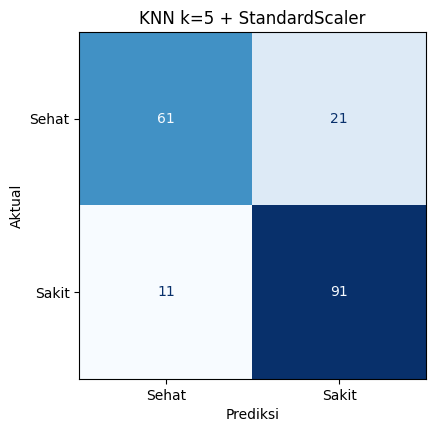

In [ ]:
# ubah angka confusion matrix jadi gambar; label 0 = Sehat, 1 = Sakit
tampilan = ConfusionMatrixDisplay(cm_standard, display_labels=["Sehat", "Sakit"])
tampilan.plot(cmap="Blues", colorbar=False)   # makin gelap kotaknya, makin banyak pasien
tampilan.ax_.set_title("KNN k=5 + StandardScaler")
tampilan.ax_.set_xlabel("Prediksi")   # kolom = prediksi
tampilan.ax_.set_ylabel("Aktual")     # baris = aktual
plt.show()

Di scikit-learn, **baris = aktual** dan **kolom = prediksi**. Kelas positif kita adalah **1 = Sakit**.

| Kotak | Posisi | Arti di kasus ini |
|---|---|---|
| **TN** (True Negative) | kiri atas | Pasien sehat, ditebak sehat |
| **FP** (False Positive) | kanan atas | Pasien sehat, ditebak **sakit** |
| **FN** (False Negative) | kiri bawah | Pasien sakit, ditebak **sehat** |
| **TP** (True Positive) | kanan bawah | Pasien sakit, ditebak sakit |

**Diskusi:** Mana yang lebih berbahaya, FP atau FN?

Bandingkan dengan model **tanpa scaling**:

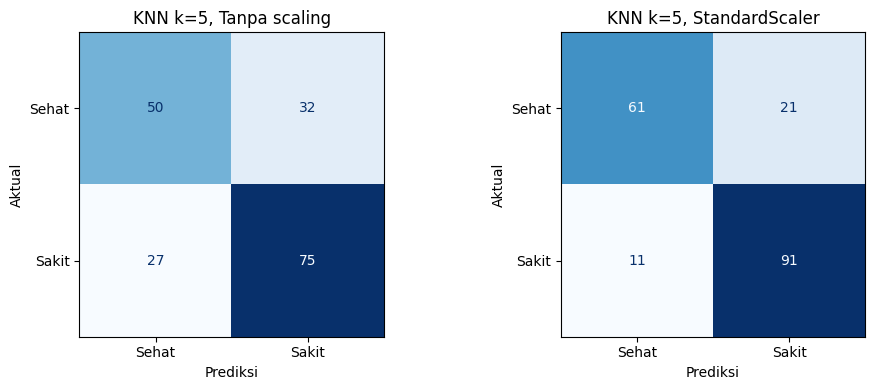

In [ ]:
cm_tanpa_scaling = confusion_matrix(y_test, pred_tanpa_scaling)   # confusion matrix model tanpa scaling

fig, axes = plt.subplots(1, 2, figsize=(10, 4))   # dua grafik berdampingan
# kiri: tanpa scaling, kanan: StandardScaler
for ax, cm, judul in zip(axes, [cm_tanpa_scaling, cm_standard], ["Tanpa scaling", "StandardScaler"]):
    # gambar confusion matrix di grafik ax
    ConfusionMatrixDisplay(cm, display_labels=["Sehat", "Sakit"]).plot(ax=ax, cmap="Blues", colorbar=False)
    ax.set_title(f"KNN k=5, {judul}")
    ax.set_xlabel("Prediksi")   # kolom = prediksi
    ax.set_ylabel("Aktual")     # baris = aktual
plt.tight_layout()
plt.show()

**Diskusi:** Scaling mengurangi FN dari berapa ke berapa?

## 8. Precision dan recall (± 10 menit)
Dari empat kotak tadi kita bisa menghitung dua metrik yang lebih tajam daripada accuracy.

**Analogi:** Razia lalu lintas. Recall: dari semua pelanggar, berapa yang tertangkap. Precision: dari semua yang ditilang, berapa yang benar-benar melanggar.

### Precision
$$\text{precision} = \frac{TP}{TP + FP}$$

Dalam bahasa awam: **dari semua yang ditebak sakit, berapa persen yang benar sakit.**

In [ ]:
# TODO: hitung precision KNN + StandardScaler. Urutan argumen: (y_aktual, y_prediksi)
prec_standard = precision_score(y_test, pred_standard)   # dari yang ditebak sakit, berapa yang benar sakit
print(f"Precision KNN + StandardScaler: {prec_standard:.1%}")

Precision KNN + StandardScaler: 81.2%


### Recall
$$\text{recall} = \frac{TP}{TP + FN}$$

Dalam bahasa awam: **dari semua pasien yang benar sakit, berapa persen yang berhasil ditemukan.**

In [ ]:
# TODO: hitung recall KNN + StandardScaler. Urutan argumen: (y_aktual, y_prediksi)
rec_standard = recall_score(y_test, pred_standard)   # dari yang benar sakit, berapa yang ditemukan
print(f"Recall KNN + StandardScaler: {rec_standard:.1%}")

Recall KNN + StandardScaler: 89.2%


In [ ]:
# kumpulkan accuracy, precision, dan recall tiga model dalam satu tabel
perbandingan_metrik = pd.DataFrame({
    "model": ["Baseline (selalu Sakit)", "KNN tanpa scaling", "KNN + StandardScaler"],
    "accuracy": [acc_baseline, acc_tanpa_scaling, acc_standard],
    "precision": [precision_score(y_test, pred_baseline), precision_score(y_test, pred_tanpa_scaling), prec_standard],
    "recall": [recall_score(y_test, pred_baseline), recall_score(y_test, pred_tanpa_scaling), rec_standard],
})
# tampilkan sebagai persen 1 desimal, tanpa nomor baris
perbandingan_metrik.style.format({"accuracy": "{:.1%}", "precision": "{:.1%}", "recall": "{:.1%}"}).hide(axis="index")

model,accuracy,precision,recall
Baseline (selalu Sakit),55.4%,55.4%,100.0%
KNN tanpa scaling,67.9%,70.1%,73.5%
KNN + StandardScaler,82.6%,81.2%,89.2%


**Diskusi:** Recall baseline 100%. Berarti baseline model terbaik?

**Diskusi:** Untuk deteksi penyakit jantung, metrik mana yang paling kalian jaga?

> **Di dunia nyata (cukup dipahami, tidak dipraktikkan):** Precision dan recall sering diringkas menjadi satu angka, **F1-score** (`classification_report` menampilkan ketiganya sekaligus). Tarik-ulur precision vs recall diatur lewat **ambang probabilitas** (`predict_proba`), misalnya pasien dianggap sakit kalau peluangnya di atas 30%, bukan 50%. Recall naik, tapi precision turun.

## 9. Pengaruh nilai k (± 6 menit)
Sejauh ini kita memakai k = 5. Bagaimana kalau tetangganya hanya 1, atau sampai 21? Semua memakai data StandardScaler.

**Analogi:** Minta rekomendasi ke 1 orang (gampang terpengaruh selera yang aneh) dibanding ke seluruh kampus (orang yang seleranya tidak mirip ikut dihitung).

In [ ]:
hasil_k = []                                        # tempat menyimpan hasil tiap k
for k in [1, 5, 21]:                                # coba tiga nilai k
    model_k = KNeighborsClassifier(n_neighbors=k)   # KNN dengan k tetangga
    model_k.fit(X_train_scaled, y_train)            # simpan data latih (sudah di-scaling)
    pred_k = model_k.predict(X_test_scaled)         # tebak data uji (sudah di-scaling)
    hasil_k.append({                                # simpan metrik k ini sebagai satu baris
        "k": k,
        "accuracy": accuracy_score(y_test, pred_k),
        "precision": precision_score(y_test, pred_k),
        "recall": recall_score(y_test, pred_k),
        "FN": confusion_matrix(y_test, pred_k)[1, 0],   # [1, 0]: baris Sakit, kolom Sehat = FN
    })

tabel_k = pd.DataFrame(hasil_k)   # daftar hasil dijadikan tabel
# tampilkan sebagai persen 1 desimal, tanpa nomor baris
tabel_k.style.format({"accuracy": "{:.1%}", "precision": "{:.1%}", "recall": "{:.1%}"}).hide(axis="index")

k,accuracy,precision,recall,FN
1,74.5%,78.4%,74.5%,26
5,82.6%,81.2%,89.2%,11
21,79.9%,79.3%,86.3%,14


**Diskusi:** Kenapa k = 1 lebih jelek dari k = 5? Kenapa k = 21 juga turun?

**Pengingat:** nilai k yang dicoba ganjil semua karena hanya ada dua kelas. Dengan k ganjil voting tidak mungkin seri (misalnya 3 lawan 2).

> **Di dunia nyata (cukup dipahami, tidak dipraktikkan):** Memilih k berdasarkan skor data uji sebenarnya juga **mengintip soal ujian**: k-nya jadi cocok dengan data uji ini saja. Cara yang benar memakai **cross-validation**, dibahas di Hari 4. KNN juga bisa memberi bobot lebih besar ke tetangga yang lebih dekat (`weights="distance"`), sehingga tetangga yang jauh tidak ikut menentukan sama kuat.

## 10. Ringkasan (± 2 menit)
| Langkah | Kode | Tujuannya |
|---|---|---|
| Cleaning untuk KNN | `.loc[...] = np.nan`, isi median/modus, 1/0, `pd.get_dummies` | Tidak ada NaN, tidak ada teks, tidak ada 0 palsu |
| Split + stratify | `train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)` | Proporsi kelas sama di train dan test |
| Scaling | `scaler.fit(X_train)`, lalu `scaler.transform(...)` | Semua kolom setara di rumus jarak |
| Fit | `knn.fit(X_train_scaled, y_train)` | KNN menyimpan data latih |
| Predict | `knn.predict(X_test_scaled)` | Voting k tetangga terdekat |
| Evaluasi | `accuracy_score`, `confusion_matrix`, `precision_score`, `recall_score` | Menilai jenis kesalahan, dibandingkan dengan baseline |

| | Hari 2 | Hari 3 |
|---|---|---|
| Jenis target | Angka (harga) → **regresi** | Kategori (sehat/sakit) → **klasifikasi** |
| Model | `LinearRegression` | `KNeighborsClassifier` |
| Perlu scaling? | Tidak, koefisien menyesuaikan satuan | **Wajib**, karena menghitung jarak |
| Baseline | Selalu menebak rata-rata | Selalu menebak kelas terbanyak |
| Metrik | MAE, RMSE, R² | Accuracy, confusion matrix, precision, recall |

**Berikutnya, Hari 4:** skor train vs test, cross-validation untuk memilih k dengan adil, dan perbandingan beberapa model termasuk Random Forest.